# Model Notebook
### Emotion Classification – Base Models + Stacking Ensemble

**Prerequisites:** Run `notebooks/preprocess.ipynb` first to generate `datasets/processed/`.

**Flow:**
1. Load processed data & config, set up grid search
2. Base model A – **Naive Bayes** (TF-IDF + MultinomialNB) – grid search → final fit
3. Base model B – **SVM** (TF-IDF + LinearSVC w/ calibration) – grid search → final fit
4. Base model C – **XGBoost** (TF-IDF + XGBClassifier) – grid search → final fit
5. **Stacking Ensemble** (out-of-fold from the *tuned* base models → tuned Logistic Regression meta-learner)
6. All models saved to `models/`

## 1. Load Processed Data & Configuration

In [86]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from sklearn.preprocessing import LabelEncoder

# ---- Load config written by preprocess.ipynb ----
PROCESSED_DIR = os.path.join("../datasets", "processed")
with open(os.path.join(PROCESSED_DIR, "config.json")) as f:
    cfg = json.load(f)

EMOTION_LABELS = cfg["EMOTION_LABELS"]
N_FOLDS        = cfg["N_FOLDS"]
SEED           = cfg["SEED"]
K              = cfg["K"]
MODELS_DIR     = cfg["MODELS_DIR"]

os.makedirs(MODELS_DIR, exist_ok=True)

# ---- Load arrays ----
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"), allow_pickle=True)
X_test  = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"),  allow_pickle=True)
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
y_test  = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))
classes = np.load(os.path.join(PROCESSED_DIR, "label_encoder_classes.npy"), allow_pickle=True)

le = LabelEncoder()
le.classes_ = classes

print(f"Train: {len(X_train):,}  |  Test: {len(X_test):,}")
print(f"Classes ({K}):", list(le.classes_))
print(f"Emotion labels: {EMOTION_LABELS}")
print(f"N_FOLDS={N_FOLDS}  SEED={SEED}  MODELS_DIR='{MODELS_DIR}'")

Train: 608  |  Test: 152
Classes (3): [np.str_('anger'), np.str_('fear'), np.str_('sadness')]
Emotion labels: ['anger', 'fear', 'sadness']
N_FOLDS=5  SEED=42  MODELS_DIR='../models'


## 1b. Grid-Search Setup

* One shared helper (`run_grid_search`) is used for every model below.
* Tuning only sees `X_train` (stratified CV). The test set is untouched until final evaluation.
* Set `RUN_GRID_SEARCH = False` to skip the search and re-use `models/best_params.json` from the last run.
* `REFIT = "f1_macro"` because the classes are imbalanced (anger ~64%). Switch to `"accuracy"` if that is what you want to optimise.

In [87]:
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold

# ---- Grid-search settings ----
RUN_GRID_SEARCH = True                       # False -> re-use models/best_params.json
SCORING   = {"accuracy": "accuracy", "f1_macro": "f1_macro"}
REFIT     = "f1_macro"                       # metric used to pick the winner
GS_CV     = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
GS_N_JOBS = -1                               # parallel over candidates (each model itself is single-threaded)
BEST_PARAMS_PATH = os.path.join(MODELS_DIR, "best_params.json")

TUNING = {}   # key -> {"params": {...}, "cv_accuracy": float, "cv_f1_macro": float}
if not RUN_GRID_SEARCH and os.path.exists(BEST_PARAMS_PATH):
    with open(BEST_PARAMS_PATH) as f:
        TUNING = json.load(f)
    for v in TUNING.values():   # JSON turns tuples into lists; sklearn wants tuples for ngram_range
        v["params"] = {k: tuple(x) if k.endswith("ngram_range") else x for k, x in v["params"].items()}


def run_grid_search(key, label, estimator, grid, X=None, y=None):
    """Exhaustive grid search with stratified CV on the training data only."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    if not RUN_GRID_SEARCH:
        if key not in TUNING:
            raise RuntimeError(f"No cached params for '{key}' - set RUN_GRID_SEARCH = True")
        print(f"[{label}] cached best params: {TUNING[key]['params']}")
        return None

    n = len(ParameterGrid(grid))
    print(f"[{label}] {n} combinations x {N_FOLDS} folds = {n * N_FOLDS} fits")
    gs = GridSearchCV(estimator, grid, scoring=SCORING, refit=REFIT, cv=GS_CV,
                      n_jobs=GS_N_JOBS, error_score="raise")
    gs.fit(X, y)

    b = gs.best_index_
    TUNING[key] = {
        "params":      gs.best_params_,
        "cv_accuracy": float(gs.cv_results_["mean_test_accuracy"][b]),
        "cv_f1_macro": float(gs.cv_results_["mean_test_f1_macro"][b]),
    }
    with open(BEST_PARAMS_PATH, "w") as f:
        json.dump(TUNING, f, indent=2)

    res = pd.DataFrame(gs.cv_results_).sort_values(f"rank_test_{REFIT}").head(5)
    cols = [c for c in res.columns if c.startswith("param_")] + [
        "mean_test_accuracy", "mean_test_f1_macro", "std_test_f1_macro"]
    print(f"[{label}] best {REFIT} (CV) = {TUNING[key]['cv_f1_macro']:.4f}"
          f"  | accuracy (CV) = {TUNING[key]['cv_accuracy']:.4f}")
    print(f"[{label}] best params: {gs.best_params_}")
    display(res[cols].round(4).reset_index(drop=True))
    return gs


def apply_best(estimator, key):
    """Return `estimator` configured with the tuned params for `key` (if any)."""
    if key in TUNING:
        estimator.set_params(**TUNING[key]["params"])
    return estimator

print(f"Grid search: {'ON' if RUN_GRID_SEARCH else 'OFF (cached)'} | refit on {REFIT} | CV = {N_FOLDS}-fold stratified")

Grid search: ON | refit on f1_macro | CV = 5-fold stratified


## Helper – Confusion Matrix Plotter

In [88]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix", figsize=(8, 6)):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(K)))
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.colorbar(im, ax=ax)
    ax.set(xticks=range(K), yticks=range(K),
           xticklabels=le.classes_, yticklabels=le.classes_,
           xlabel="Predicted label", ylabel="True label",
           title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}",
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.show()


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1-macro : {f1:.4f}")
    print()
    print(classification_report(y_true, y_pred,
                                 target_names=le.classes_,
                                 zero_division=0))
    plot_confusion_matrix(y_true, y_pred, title=f"Confusion Matrix – {name}")

print("Helper functions ready.")

Helper functions ready.


## Data Exploration & Word Clouds

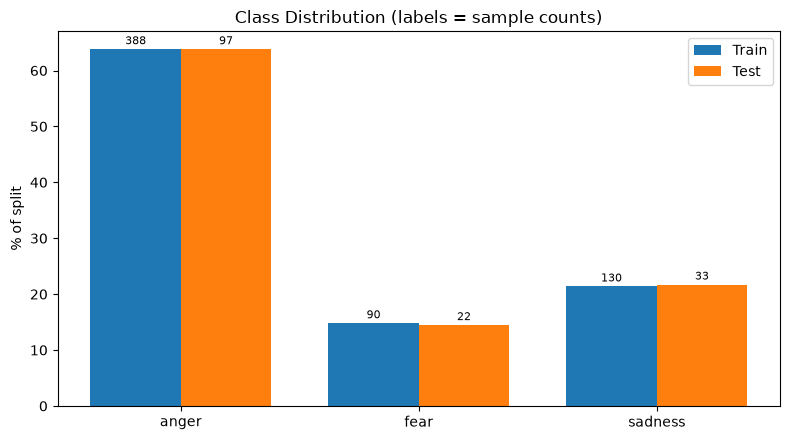

In [89]:
import os
import pandas as pd
from collections import Counter
from wordcloud import WordCloud, STOPWORDS

FIG_DIR = os.path.join("figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

CLASS_NAMES = [str(c) for c in le.classes_]
texts_train = [str(t) for t in X_train]
texts_test  = [str(t) for t in X_test]

# Add your own stop-words here (e.g. Indonesian ones) if the clouds are dominated by filler words
EXTRA_STOPWORDS = set()
STOP = set(STOPWORDS) | EXTRA_STOPWORDS

# ---- Class distribution (train vs test) ----
train_counts = np.bincount(y_train, minlength=K)
test_counts  = np.bincount(y_test,  minlength=K)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(K); w = 0.38
b1 = ax.bar(x - w/2, train_counts / train_counts.sum() * 100, w, label="Train")
b2 = ax.bar(x + w/2, test_counts  / test_counts.sum()  * 100, w, label="Test")
for bars, cnt in ((b1, train_counts), (b2, test_counts)):
    for rect, c in zip(bars, cnt):
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.4, str(c),
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("% of split"); ax.set_title("Class Distribution (labels = sample counts)")
ax.legend(); plt.tight_layout(); save_fig("class_distribution"); plt.show()

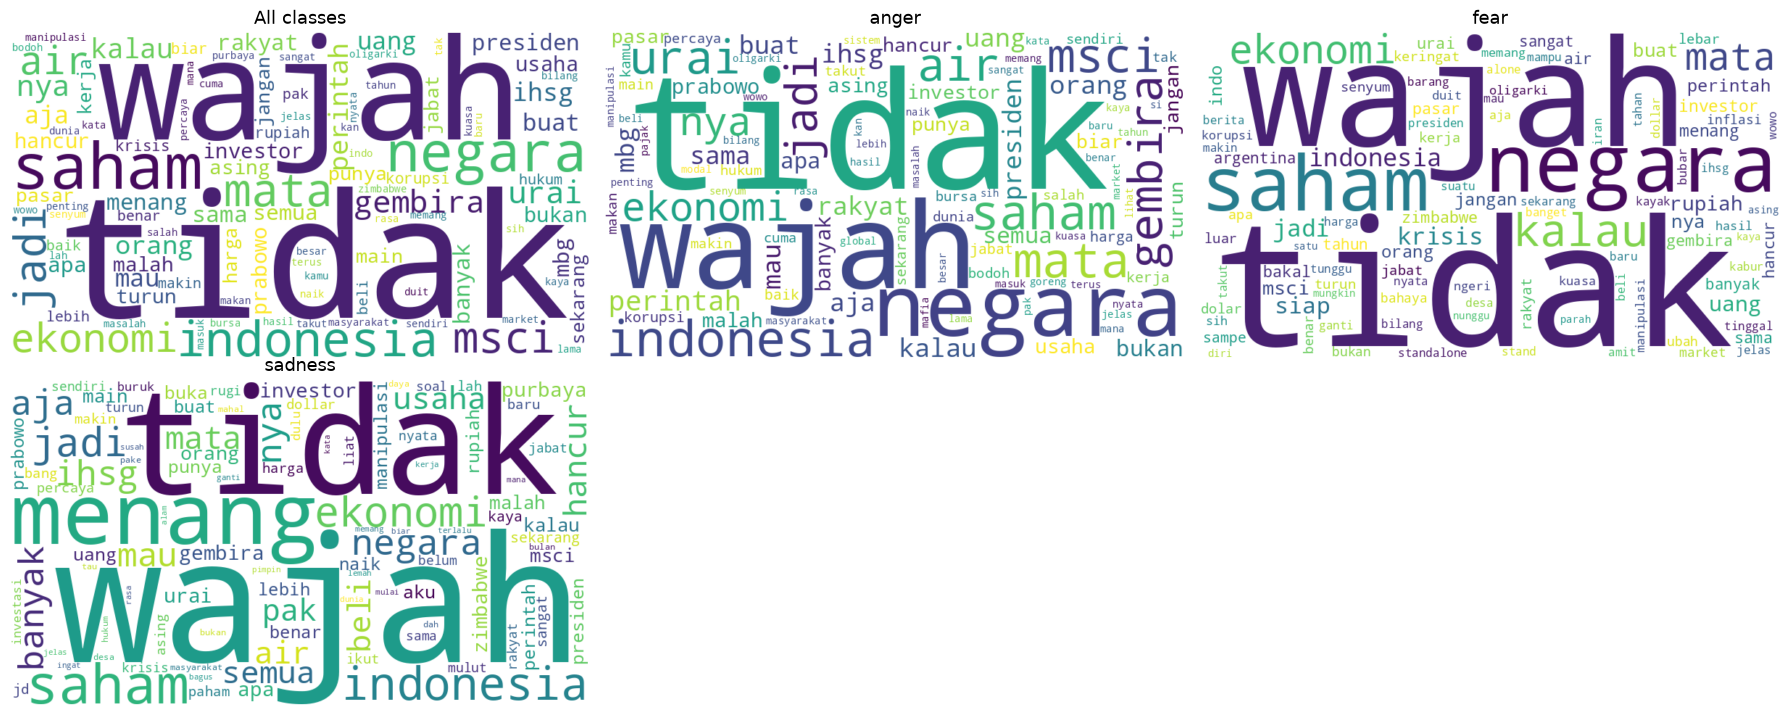

In [90]:
# ---- Word cloud per class + overall ----
def make_cloud(text):
    if not text.strip():
        return None
    return WordCloud(width=800, height=450, background_color="white",
                     stopwords=STOP, collocations=False, max_words=100,
                     random_state=SEED).generate(text)

panels = [("All classes", " ".join(texts_train))] + [
    (name, " ".join(t for t, y in zip(texts_train, y_train) if y == i))
    for i, name in enumerate(CLASS_NAMES)
]

ncols = 3
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, (title, text) in zip(axes.ravel(), panels):
    wc = make_cloud(text)
    if wc is not None:
        ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=13); ax.axis("off")
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
plt.tight_layout(); save_fig("wordclouds_per_class"); plt.show()

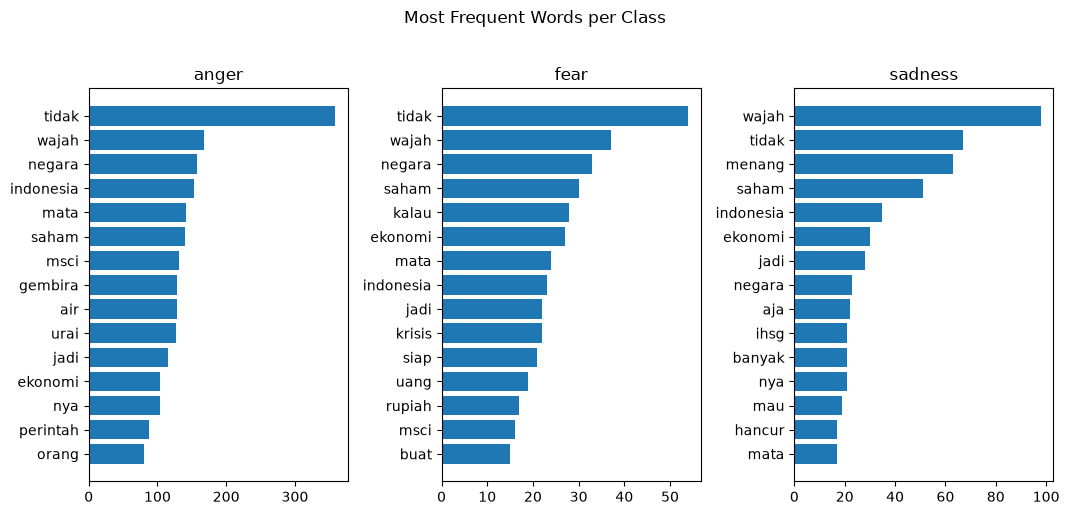

In [91]:
# ---- Top-15 most frequent words per class ----
TOP_N = 15
fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 5), sharex=False)
for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), CLASS_NAMES)):
    words = " ".join(t for t, y in zip(texts_train, y_train) if y == i).lower().split()
    cnt = Counter(w for w in words if w not in STOP and len(w) > 2).most_common(TOP_N)
    if cnt:
        labels, vals = zip(*cnt)
        ax.barh(labels[::-1], vals[::-1])
    ax.set_title(name)
plt.suptitle("Most Frequent Words per Class", y=1.02)
plt.tight_layout(); save_fig("top_words_per_class"); plt.show()

## 2. Base Model A – Naive Bayes

### 2.1 Grid search

In [92]:
from sklearn.naive_bayes import MultinomialNB

def _nb_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   MultinomialNB(alpha=0.5)),
    ])

NB_GRID = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df":      [1, 2, 3, 5],
    "clf__alpha":         [0.05, 0.1, 0.3, 0.5, 1.0, 2.0],
    "clf__fit_prior":     [True, False],     # False = uniform class prior (helps minority classes)
}
gs_nb = run_grid_search("nb", "Naive Bayes", _nb_base(), NB_GRID)

[Naive Bayes] 96 combinations x 5 folds = 480 fits
[Naive Bayes] best f1_macro (CV) = 0.6109  | accuracy (CV) = 0.7155
[Naive Bayes] best params: {'clf__alpha': 1.0, 'clf__fit_prior': False, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}


,param_clf__alpha,param_clf__fit_prior,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,1.00,False,3,"(1, 1)",0.7155,0.6109,0.0260
1,0.30,False,3,"(1, 2)",0.6909,0.6007,0.0420
2,0.05,False,1,"(1, 1)",0.6925,0.5989,0.0508
3,0.10,False,1,"(1, 1)",0.7040,0.5985,0.0359
4,0.50,False,3,"(1, 1)",0.6909,0.5984,0.0436


### 2.2 Final model (best params, evaluated on the test set)

Naive Bayes model saved to '../models/naive_bayes.pkl'
=== Naive Bayes ===
Accuracy : 0.7171
F1-macro : 0.5734

              precision    recall  f1-score   support

       anger       0.74      0.92      0.82        97
        fear       0.54      0.32      0.40        22
     sadness       0.68      0.39      0.50        33

    accuracy                           0.72       152
   macro avg       0.65      0.54      0.57       152
weighted avg       0.70      0.72      0.69       152



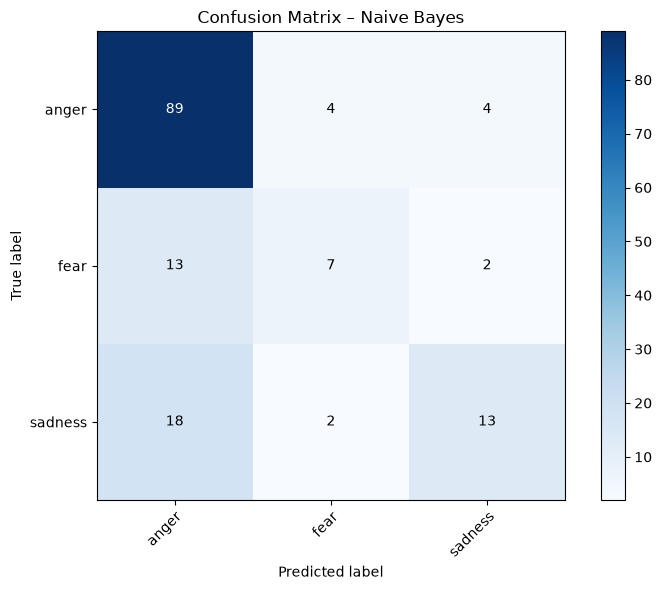

In [93]:
import joblib

def make_nb():
    return apply_best(_nb_base(), "nb")     # tuned params from the grid search above

nb_model = make_nb()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

# Save
nb_path = os.path.join(MODELS_DIR, "naive_bayes.pkl")
joblib.dump(nb_model, nb_path)
print(f"Naive Bayes model saved to '{nb_path}'")

evaluate("Naive Bayes", y_test, y_pred_nb)

## 3. Base Model B – SVM

### 3.1 Grid search

In [94]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

def _svm_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        # random_state: LinearSVC (liblinear) shuffles data internally -> unseeded = different result every run
        ("clf",   CalibratedClassifierCV(
                      LinearSVC(class_weight="balanced", random_state=SEED, max_iter=10000), cv=3)),
    ])

SVM_GRID = {
    "tfidf__ngram_range":        [(1, 1), (1, 2)],
    "tfidf__min_df":             [1, 2],
    "clf__estimator__C":         [0.1, 0.3, 1, 3, 10],
    "clf__estimator__class_weight": [None, "balanced"],
}
gs_svm = run_grid_search("svm", "SVM", _svm_base(), SVM_GRID)

[SVM] 40 combinations x 5 folds = 200 fits
[SVM] best f1_macro (CV) = 0.6259  | accuracy (CV) = 0.7500
[SVM] best params: {'clf__estimator__C': 3, 'clf__estimator__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


,param_clf__estimator__C,param_clf__estimator__class_weight,param_tfidf__min_df,param_tfidf__ngram_range,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,3.0,NaN,1,"(1, 2)",0.75,0.6259,0.0217
1,3.0,balanced,1,"(1, 2)",0.75,0.6259,0.0217
2,10.0,balanced,1,"(1, 2)",0.75,0.6250,0.0215
3,10.0,NaN,1,"(1, 2)",0.75,0.6250,0.0215
4,1.0,NaN,1,"(1, 2)",0.75,0.6241,0.0252


### 3.2 Final model (best params, evaluated on the test set)

SVM model saved to '../models/svm.pkl'
=== SVM ===
Accuracy : 0.7434
F1-macro : 0.6100

              precision    recall  f1-score   support

       anger       0.75      0.95      0.84        97
        fear       0.64      0.41      0.50        22
     sadness       0.75      0.36      0.49        33

    accuracy                           0.74       152
   macro avg       0.72      0.57      0.61       152
weighted avg       0.74      0.74      0.71       152



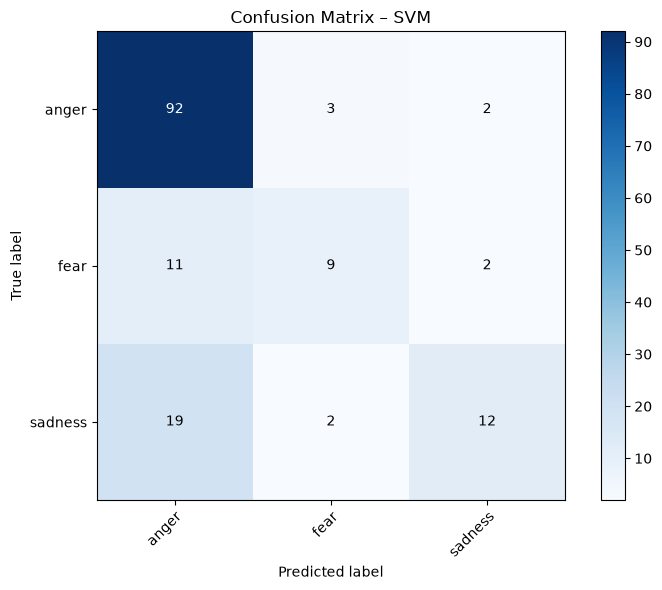

In [95]:
def make_svm():
    return apply_best(_svm_base(), "svm")   # tuned params from the grid search above

svm_model = make_svm()
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

# Save
svm_path = os.path.join(MODELS_DIR, "svm.pkl")
joblib.dump(svm_model, svm_path)
print(f"SVM model saved to '{svm_path}'")

evaluate("SVM", y_test, y_pred_svm)

## 4. Base Model C – XGBoost

### 4.1 Grid search

In [96]:
from xgboost import XGBClassifier

def _xgb_base():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=SEED,
            n_jobs=1,          # multi-threaded float reductions can change results; GridSearchCV parallelises instead
        )),
    ])

XGB_GRID = {
    "clf__n_estimators":     [100, 300, 500],
    "clf__learning_rate":    [0.05, 0.1],
    "clf__max_depth":        [2, 3, 6],
    "clf__colsample_bytree": [0.5, 1.0],
}
gs_xgb = run_grid_search("xgb", "XGBoost", _xgb_base(), XGB_GRID)

[XGBoost] 36 combinations x 5 folds = 180 fits
[XGBoost] best f1_macro (CV) = 0.5763  | accuracy (CV) = 0.7139
[XGBoost] best params: {'clf__colsample_bytree': 0.5, 'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 500}


,param_clf__colsample_bytree,param_clf__learning_rate,param_clf__max_depth,param_clf__n_estimators,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,0.5,0.10,3,500,0.7139,0.5763,0.0388
1,0.5,0.10,2,500,0.7172,0.5759,0.0449
2,1.0,0.10,3,300,0.7204,0.5676,0.0355
3,0.5,0.05,3,500,0.7237,0.5672,0.0340
4,1.0,0.10,2,500,0.7172,0.5645,0.0424


### 4.2 Final model (best params, evaluated on the test set)

XGBoost model saved to '../models/xgboost.pkl'
=== XGBoost ===
Accuracy : 0.7171
F1-macro : 0.5220

              precision    recall  f1-score   support

       anger       0.74      0.96      0.84        97
        fear       0.50      0.18      0.27        22
     sadness       0.63      0.36      0.46        33

    accuracy                           0.72       152
   macro avg       0.63      0.50      0.52       152
weighted avg       0.68      0.72      0.67       152



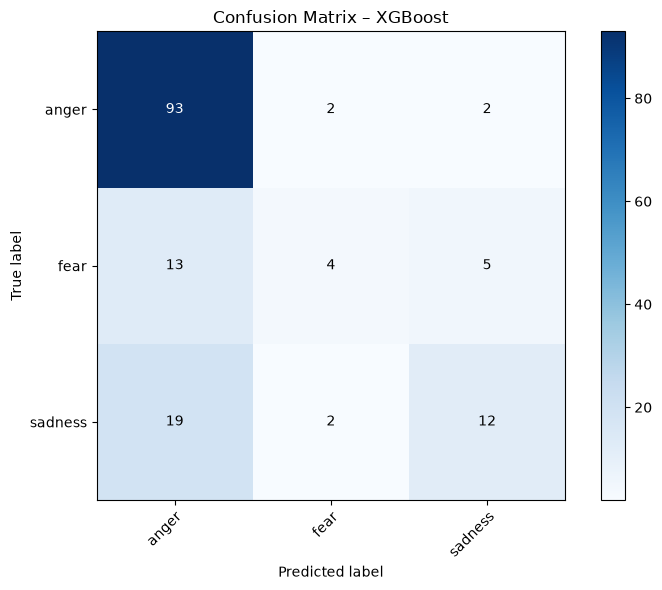

In [97]:
def make_xgb():
    return apply_best(_xgb_base(), "xgb")   # tuned params from the grid search above

xgb_model = make_xgb()
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

# Save
xgb_path = os.path.join(MODELS_DIR, "xgboost.pkl")
joblib.dump(xgb_model, xgb_path)
print(f"XGBoost model saved to '{xgb_path}'")

evaluate("XGBoost", y_test, y_pred_xgb)

## 5. Stacking Ensemble

**Strategy:** Out-of-fold (OOF) predictions from the three base models become
features for a Logistic Regression meta-learner.  This avoids data leakage
because each training fold's predictions are made by a model that never saw
those samples during training.

```
              [NB proba] [SVM proba] [XGB proba]
                         ↓
              Logistic Regression (meta-learner)
                         ↓
                  Emotion prediction
```

### 5.1 Generate Out-of-Fold Predictions

In [98]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
n_train = len(X_train)

oof = {
    "nb":  np.zeros((n_train, K)),
    "svm": np.zeros((n_train, K)),
    "xgb": np.zeros((n_train, K)),
}

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"Fold {fold}/{N_FOLDS}")
    Xtr, Xva = X_train[tr_idx], X_train[va_idx]
    ytr = y_train[tr_idx]

    nb_f  = make_nb().fit(Xtr, ytr)
    svm_f = make_svm().fit(Xtr, ytr)
    xgb_f = make_xgb().fit(Xtr, ytr)

    oof["nb"][va_idx]  = nb_f.predict_proba(Xva)
    oof["svm"][va_idx] = svm_f.predict_proba(Xva)
    oof["xgb"][va_idx] = xgb_f.predict_proba(Xva)

print("OOF prediction complete.")

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
OOF prediction complete.


### 5.2 Tune & Train Meta-Learner

In [99]:
from sklearn.linear_model import LogisticRegression

meta_train = np.hstack([oof["nb"], oof["svm"], oof["xgb"]])

# Tune the meta-learner on the out-of-fold features (CV over rows of meta_train)
META_GRID = {
    "C":            [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"],
}
gs_meta = run_grid_search("meta", "Meta-learner (LogReg)",
                          LogisticRegression(max_iter=2000, random_state=SEED),
                          META_GRID, X=meta_train, y=y_train)

meta_learner = apply_best(LogisticRegression(max_iter=2000, random_state=SEED), "meta")
meta_learner.fit(meta_train, y_train)
print("Meta-learner (Logistic Regression) trained with:", TUNING.get("meta", {}).get("params", "defaults"))

[Meta-learner (LogReg)] 10 combinations x 5 folds = 50 fits
[Meta-learner (LogReg)] best f1_macro (CV) = 0.6201  | accuracy (CV) = 0.7467
[Meta-learner (LogReg)] best params: {'C': 1, 'class_weight': None}


,param_C,param_class_weight,mean_test_accuracy,mean_test_f1_macro,std_test_f1_macro
0,1.00,NaN,0.7467,0.6201,0.0148
1,10.00,NaN,0.7434,0.6171,0.0192
2,100.00,NaN,0.7418,0.6155,0.0192
3,0.10,balanced,0.6991,0.6131,0.0334
4,0.01,balanced,0.7056,0.6126,0.0328


Meta-learner (Logistic Regression) trained with: {'C': 1, 'class_weight': None}


### 5.3 Evaluate Stacking Ensemble on Test Set

=== Stacking Ensemble (NB + SVM + XGBoost) ===
Accuracy : 0.7434
F1-macro : 0.6115

              precision    recall  f1-score   support

       anger       0.75      0.95      0.84        97
        fear       0.69      0.41      0.51        22
     sadness       0.71      0.36      0.48        33

    accuracy                           0.74       152
   macro avg       0.72      0.57      0.61       152
weighted avg       0.73      0.74      0.71       152



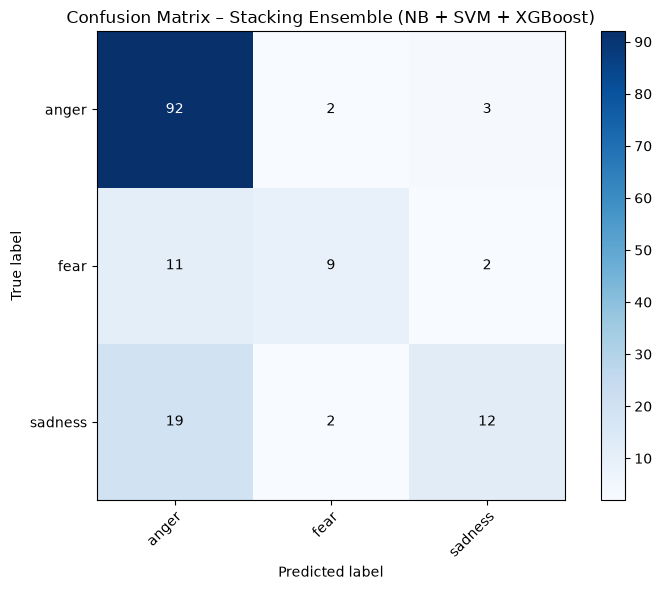

In [100]:
# Generate test-set probabilities from each base model (trained on full train set)
p_nb  = nb_model.predict_proba(X_test)
p_svm = svm_model.predict_proba(X_test)
p_xgb = xgb_model.predict_proba(X_test)

meta_test  = np.hstack([p_nb, p_svm, p_xgb])
y_pred_ens = meta_learner.predict(meta_test)

evaluate("Stacking Ensemble (NB + SVM + XGBoost)", y_test, y_pred_ens)

## 6. Save All Models

In [101]:
# Base models were already saved individually above.
# Save the meta-learner.
meta_path = os.path.join(MODELS_DIR, "meta_learner.pkl")
joblib.dump(meta_learner, meta_path)

# Save the label-encoder classes so inference code can reconstruct it
le_path = os.path.join(MODELS_DIR, "label_encoder_classes.npy")
np.save(le_path, le.classes_)

print("All models saved:")
for fname in ["naive_bayes.pkl", "svm.pkl", "xgboost.pkl",
              "meta_learner.pkl", "label_encoder_classes.npy"]:
    fpath = os.path.join(MODELS_DIR, fname)
    size  = os.path.getsize(fpath) / 1024
    print(f"  {fpath}  ({size:.1f} KB)")

All models saved:
  ../models/naive_bayes.pkl  (66.6 KB)
  ../models/svm.pkl  (1641.8 KB)
  ../models/xgboost.pkl  (1442.3 KB)
  ../models/meta_learner.pkl  (1.1 KB)
  ../models/label_encoder_classes.npy  (0.2 KB)


## 7. Summary Comparison

In [102]:
import pandas as pd

results = []
for name, y_pred in [
    ("Naive Bayes", y_pred_nb),
    ("SVM",         y_pred_svm),
    ("XGBoost",     y_pred_xgb),
    ("Ensemble",    y_pred_ens),
]:
    results.append({
        "Model":    name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1-macro": round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4),
    })

summary = pd.DataFrame(results).set_index("Model")
print(summary.to_string())
summary

             Accuracy  F1-macro
Model                          
Naive Bayes    0.7171    0.5734
SVM            0.7434    0.6100
XGBoost        0.7171    0.5220
Ensemble       0.7434    0.6115


,Accuracy,F1-macro
Model,,
Naive Bayes,0.7171,0.5734
SVM,0.7434,0.6100
XGBoost,0.7171,0.5220
Ensemble,0.7434,0.6115


## 8. Output Analysis & Visualizations

Everything below uses the already-trained models and test-set predictions. Figures are also saved to `figures/`.

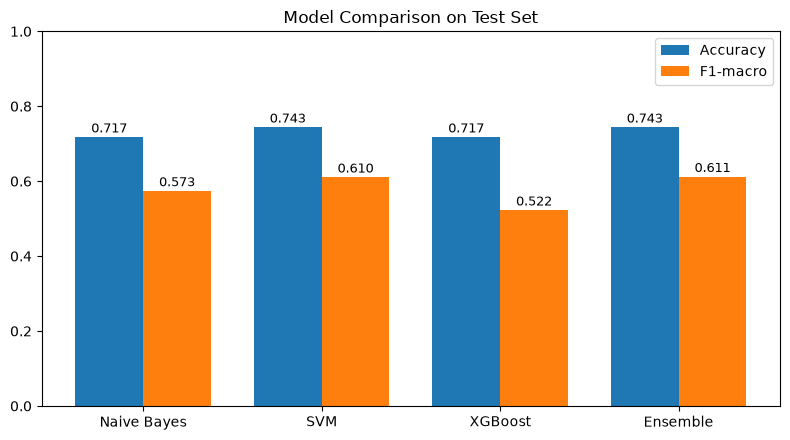

In [103]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

preds = {
    "Naive Bayes": y_pred_nb,
    "SVM":         y_pred_svm,
    "XGBoost":     y_pred_xgb,
    "Ensemble":    y_pred_ens,
}
proba_ens = meta_learner.predict_proba(meta_test)
y_test_bin = label_binarize(y_test, classes=list(range(K)))

# ---- 8.1 Overall model comparison ----
acc = [accuracy_score(y_test, p) for p in preds.values()]
f1m = [f1_score(y_test, p, average="macro", zero_division=0) for p in preds.values()]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(preds)); w = 0.38
r1 = ax.bar(x - w/2, acc, w, label="Accuracy")
r2 = ax.bar(x + w/2, f1m, w, label="F1-macro")
for r in list(r1) + list(r2):
    ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.005, f"{r.get_height():.3f}",
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(preds.keys()); ax.set_ylim(0, 1)
ax.set_title("Model Comparison on Test Set"); ax.legend()
plt.tight_layout(); save_fig("model_comparison"); plt.show()

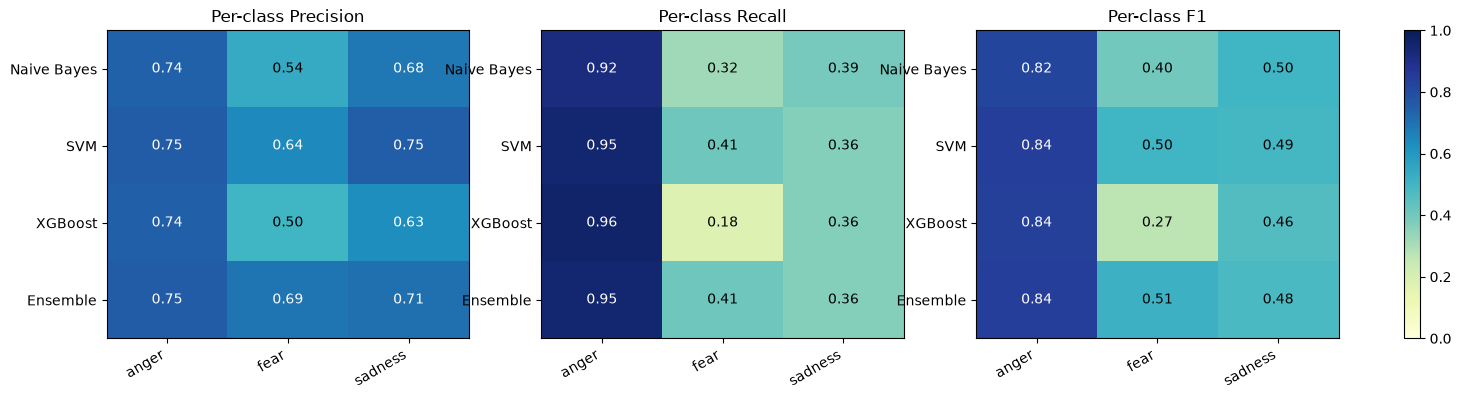

In [104]:
# ---- 8.2 Per-class F1 / precision / recall heatmaps ----
metrics = {"Precision": 0, "Recall": 1, "F1": 2}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (mname, midx) in zip(axes, metrics.items()):
    mat = np.array([
        precision_recall_fscore_support(y_test, p, labels=list(range(K)), zero_division=0)[midx]
        for p in preds.values()
    ])
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(len(preds))); ax.set_yticklabels(preds.keys())
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                    color="white" if mat[i, j] > 0.6 else "black")
    ax.set_title(f"Per-class {mname}")
plt.colorbar(im, ax=axes, fraction=0.015)
save_fig("per_class_metrics"); plt.show()

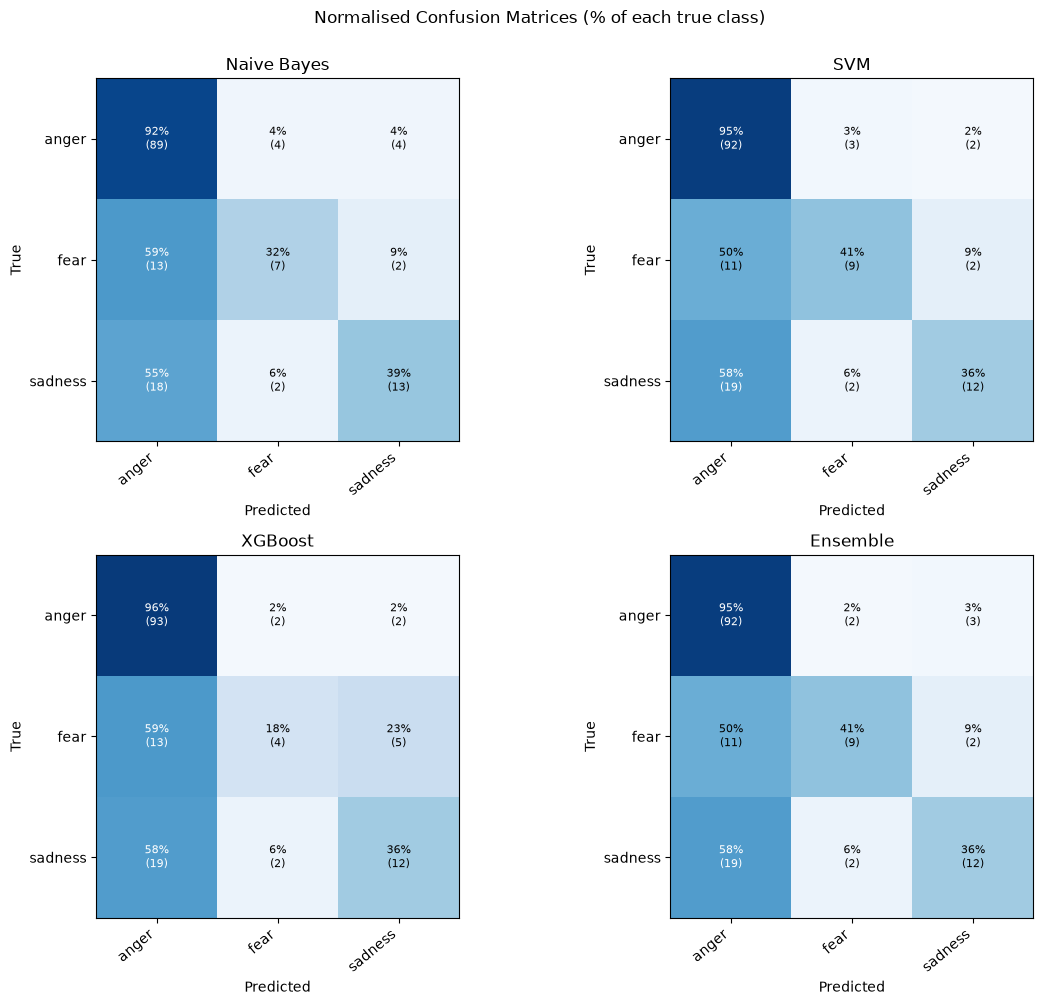

In [105]:
# ---- 8.3 Row-normalised confusion matrices (recall view) for all models ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p, labels=list(range(K)))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.suptitle("Normalised Confusion Matrices (% of each true class)", y=1.00)
plt.tight_layout(); save_fig("confusion_matrices_normalised"); plt.show()

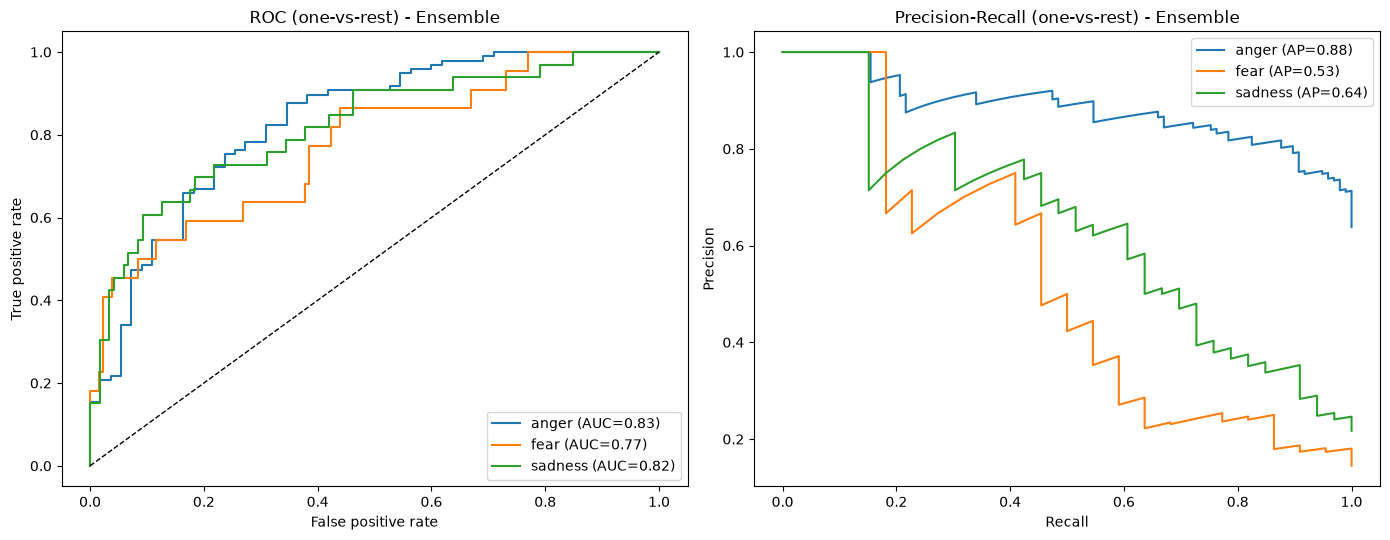

In [106]:
# ---- 8.4 ROC and Precision-Recall curves (one-vs-rest, Ensemble) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba_ens[:, i])
    ax1.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], proba_ens[:, i])
    ax2.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test_bin[:, i], proba_ens[:, i]):.2f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest) - Ensemble")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (one-vs-rest) - Ensemble")
ax1.legend(loc="lower right"); ax2.legend(loc="upper right")
plt.tight_layout(); save_fig("roc_pr_ensemble"); plt.show()

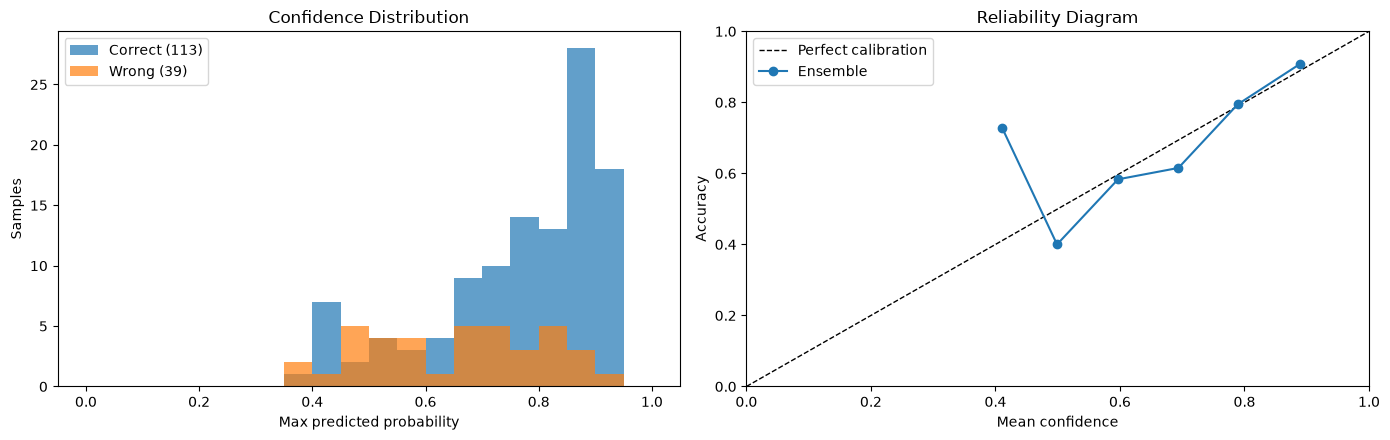

In [107]:
# ---- 8.5 Confidence: correct vs wrong predictions (Ensemble) ----
conf = proba_ens.max(axis=1)
correct = (y_pred_ens == y_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(0, 1, 21)
ax1.hist(conf[correct],  bins=bins, alpha=0.7, label=f"Correct ({correct.sum()})")
ax1.hist(conf[~correct], bins=bins, alpha=0.7, label=f"Wrong ({(~correct).sum()})")
ax1.set(xlabel="Max predicted probability", ylabel="Samples", title="Confidence Distribution")
ax1.legend()

# Reliability: accuracy per confidence bin
edges = np.linspace(conf.min(), conf.max(), 7)
idx = np.digitize(conf, edges[1:-1])
bin_acc  = [correct[idx == b].mean() if (idx == b).any() else np.nan for b in range(6)]
bin_conf = [conf[idx == b].mean()    if (idx == b).any() else np.nan for b in range(6)]
ax2.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax2.plot(bin_conf, bin_acc, "o-", label="Ensemble")
ax2.set(xlabel="Mean confidence", ylabel="Accuracy", title="Reliability Diagram", xlim=(0, 1), ylim=(0, 1))
ax2.legend()
plt.tight_layout(); save_fig("confidence_analysis"); plt.show()

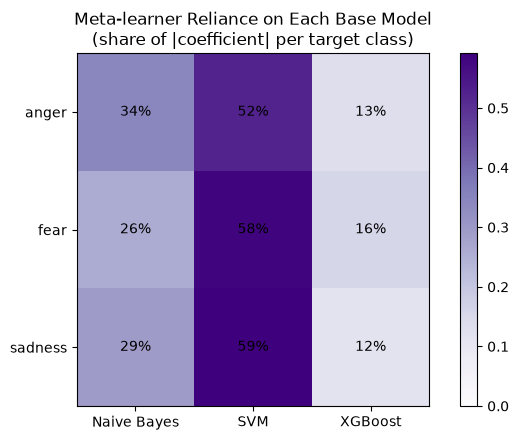

In [108]:
# ---- 8.6 Which base model does the meta-learner trust, per class? ----
# meta_learner.coef_ has shape (K, 3*K): [NB probs | SVM probs | XGB probs]
coef = meta_learner.coef_
base_names = ["Naive Bayes", "SVM", "XGBoost"]
weight = np.array([[np.abs(coef[c, b*K:(b+1)*K]).sum() for b in range(3)] for c in range(K)])
weight = weight / weight.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(weight, cmap="Purples", vmin=0, vmax=weight.max())
ax.set_xticks(range(3)); ax.set_xticklabels(base_names)
ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
for i in range(K):
    for j in range(3):
        ax.text(j, i, f"{weight[i, j]:.0%}", ha="center", va="center")
ax.set_title("Meta-learner Reliance on Each Base Model\n(share of |coefficient| per target class)")
plt.colorbar(im, ax=ax); plt.tight_layout(); save_fig("meta_learner_weights"); plt.show()

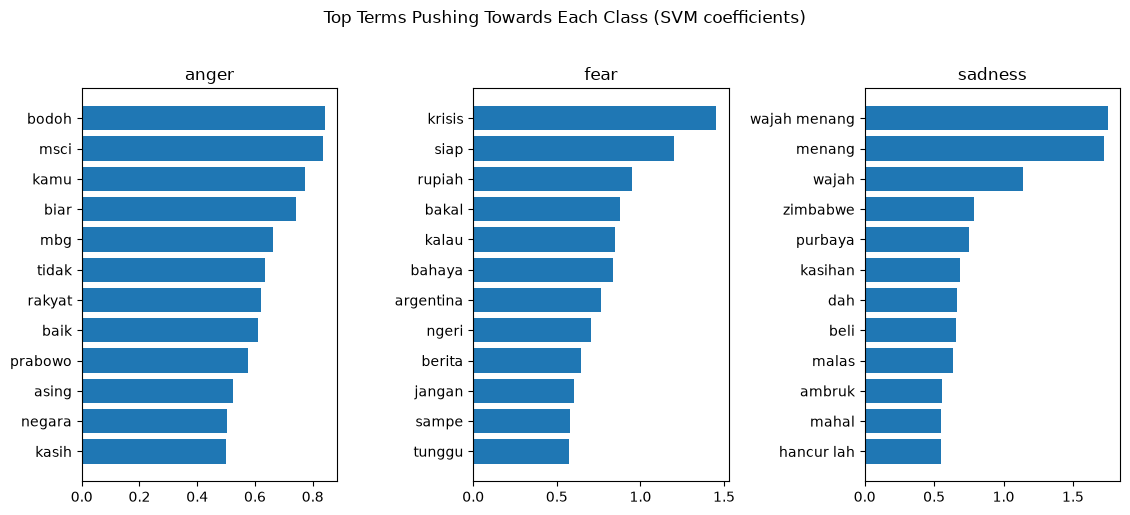

In [109]:
# ---- 8.7 Most discriminative terms per class (from the linear SVM) ----
tfidf = svm_model.named_steps["tfidf"]
vocab = np.array(tfidf.get_feature_names_out())
cal = svm_model.named_steps["clf"]
coefs = []
for cc in cal.calibrated_classifiers_:
    est = getattr(cc, "estimator", None)
    if est is None:
        est = cc.base_estimator
    coefs.append(est.coef_)
svm_coef = np.mean(coefs, axis=0)           # (K, n_features)

TOP = 12
fig, axes = plt.subplots(1, K, figsize=(3.8 * K, 5))
for i, ax in enumerate(np.atleast_1d(axes)):
    top = np.argsort(svm_coef[i])[-TOP:]
    ax.barh(vocab[top], svm_coef[i][top])
    ax.set_title(CLASS_NAMES[i])
plt.suptitle("Top Terms Pushing Towards Each Class (SVM coefficients)", y=1.02)
plt.tight_layout(); save_fig("svm_top_terms"); plt.show()

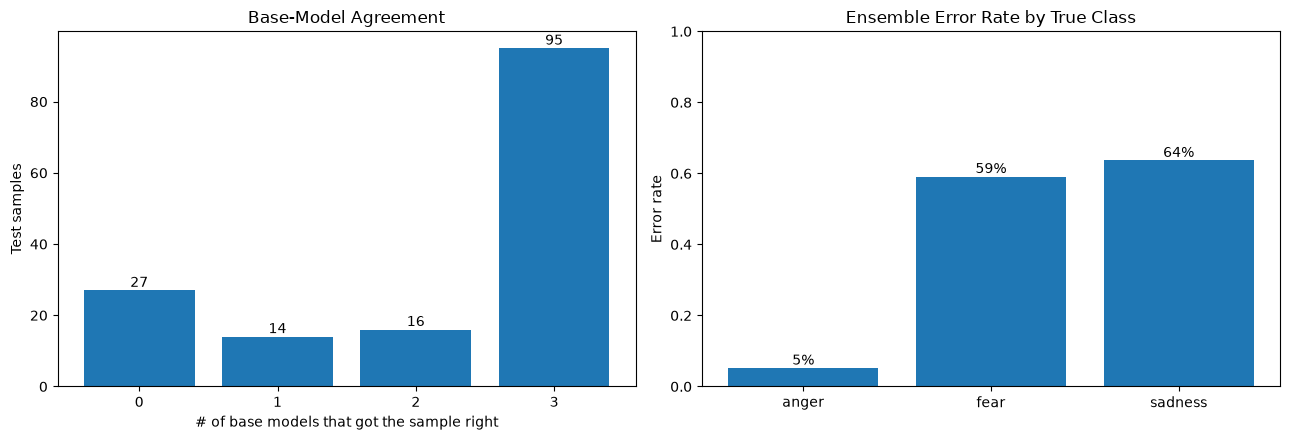

,text,true,pred,confidence
95,wajah gembira urai air mata wajah gembira urai air mata wajah gembira urai air mata begini kerja menkeu baru capek p...,sadness,anger,0.907
51,jangan lindung gelintir pihak juta rakyat justru ikut tanggung dampak anjlok ihsg lindung investor ungkap fakta jang...,fear,anger,0.896
114,lagi emang ni negara tidak inovasi kok mana investor asing mau gambling sini bandingin sama saham asing top basic ny...,sadness,anger,0.894
11,harus presiden buat nyata pers minta maaf sekarang kalau percaya rakyat rupiah turun drastis hancur zona merah bukan...,fear,anger,0.867
131,dulu jaman soeharto imf sekarang ganti msci sengaja mendowngred bursa efek indonesia biar jadi kacau mana ujung nya,fear,anger,0.843
14,investor lokal suruh nambal wajah gembira urai air mata wajah gembira urai air mata kasihan investor lokal,sadness,anger,0.830
115,butuh bas tahun negara ihsg perintah prabowo butuh bulan buat jadi,sadness,anger,0.814
107,kalau tani ternak bantu sekarang tinggal buruh pabrik pegawai swasta gaji umr gaji segitu aja naik tiap tahun tidak ...,sadness,anger,0.809
2,puncak bobrok pasar modal indonesia mudah haji isam paksa byan jual murah bantu dana bang mandra tekan regulator men...,fear,anger,0.809
34,tampar keras dunia pasar modal cermin bobrok hukum sistem perintah lama pasar dunia sdh mulai jauh pasar modal alama...,sadness,anger,0.768


In [110]:
# ---- 8.8 Model agreement & error analysis ----
base_correct = np.vstack([
    (y_pred_nb  == y_test),
    (y_pred_svm == y_test),
    (y_pred_xgb == y_test),
]).sum(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
vals = np.bincount(base_correct, minlength=4)
ax1.bar(range(4), vals)
for i, v in enumerate(vals):
    ax1.text(i, v + 1, str(v), ha="center")
ax1.set_xticks(range(4)); ax1.set_xlabel("# of base models that got the sample right")
ax1.set_ylabel("Test samples"); ax1.set_title("Base-Model Agreement")

# Error rate per true class (Ensemble)
err_rate = [(y_pred_ens[y_test == i] != i).mean() for i in range(K)]
ax2.bar(CLASS_NAMES, err_rate)
for i, v in enumerate(err_rate):
    ax2.text(i, v + 0.01, f"{v:.0%}", ha="center")
ax2.set_ylim(0, 1); ax2.set_ylabel("Error rate"); ax2.set_title("Ensemble Error Rate by True Class")
plt.tight_layout(); save_fig("agreement_and_errors"); plt.show()

# Most confident mistakes -> worth reading manually (label noise? ambiguous text?)
err_df = pd.DataFrame({
    "text":       texts_test,
    "true":       [CLASS_NAMES[i] for i in y_test],
    "pred":       [CLASS_NAMES[i] for i in y_pred_ens],
    "confidence": conf.round(3),
})
err_df = err_df[err_df["true"] != err_df["pred"]].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 120)
err_df.head(15)